TensorFlow 2.21.0

TASK 1 - LOAD DATASET, HANDLE MISSING VALUES, PREPROCESS TEXT


100%|██████████| 207k/207k [00:00<00:00, 13.8MB/s]

Extracting files...
Using file: /root/.cache/kagglehub/datasets/vishakhdapat/sms-spam-detection-dataset/versions/1/spam_sms.csv
Raw shape: (5572, 2)

Missing values per column:
 label    0
text     0

Duplicate messages: 414



Label counts:
 label
ham     4825
spam     747
--- Missing values, duplicates, labels, 2,000-message subset ---
After cleaning: 5158 messages (removed 414)
Subset used: 2000 messages | spam = 249 (12.4%) | ham = 1751
--- Text preprocessing (raw -> clean) ---
RAW   : Aight ill get on fb in a couple minutes
CLEAN : aight ill get on fb in a couple minutes

RAW   : I havent add Ì_ yet right..
CLEAN : i havent add yet right

RAW   : As one of our registered subscribers u can enter the draw 4 a 100 G.B. gift voucher by replying with ENTER. To unsubscribe text STOP
CLEAN : as one of our registered subscribers u can enter the draw num a num g b gift voucher by replying with enter to unsubscribe text stop


TASK 2 - TOKENIZE AND PAD SEQUENCES
Train: 1400 | Validation: 200 | Test: 400
Spam share -> train 0.124 | val 0.125 | test 0.125
Distinct words in training set: 3610
MAX_LEN (95th percentile of message length): 34
Padded shapes: (1400, 34) (200, 34) (400, 34)

Text     : po de no need job a

Model: "gru_spam_classifier"

...

 Trainable params: 219,073 (855.75 KB)

 Non-trainable params: 0 (0.00 B)


TASK 3 (cont.) - RNN vs LSTM vs GRU (validation set)


,model,parameters,epochs run,train time (s),val accuracy,val precision,val recall,val F1
0,RNN,202369,11,20.9,0.995,0.962,1.0,0.98
1,LSTM,227137,9,15.4,0.995,0.962,1.0,0.98
2,GRU,219073,30,44.5,1.000,1.000,1.0,1.00



TASK 4 - TRAINING THE GRU
Epoch 1/30
44/44 - 6s - 130ms/step - accuracy: 0.6329 - loss: 0.6700 - val_accuracy: 0.8950 - val_loss: 0.6059
Epoch 2/30
44/44 - 1s - 28ms/step - accuracy: 0.9479 - loss: 0.2688 - val_accuracy: 0.9700 - val_loss: 0.1606
Epoch 3/30
44/44 - 1s - 28ms/step - accuracy: 0.9864 - loss: 0.0933 - val_accuracy: 0.9600 - val_loss: 0.1350
Epoch 4/30
44/44 - 1s - 27ms/step - accuracy: 0.9957 - loss: 0.0368 - val_accuracy: 0.9900 - val_loss: 0.0433
Epoch 5/30
44/44 - 2s - 37ms/step - accuracy: 0.9986 - loss: 0.0161 - val_accuracy: 0.9600 - val_loss: 0.1348
Epoch 6/30
44/44 - 1s - 27ms/step - accuracy: 0.9986 - loss: 0.0062 - val_accuracy: 0.9950 - val_loss: 0.0189
Epoch 7/30
44/44 - 1s - 30ms/step - accuracy: 0.9979 - loss: 0.0048 - val_accuracy: 0.9750 - val_loss: 0.1087
Epoch 8/30
44/44 - 2s - 45ms/step - accuracy: 0.9986 - loss: 0.0031 - val_accuracy: 1.0000 - val_loss: 0.0098
Epoch 9/30
44/44 - 2s - 38ms/step - accuracy: 0.9993 - loss: 0.0031 - val_accuracy: 0.9800 -

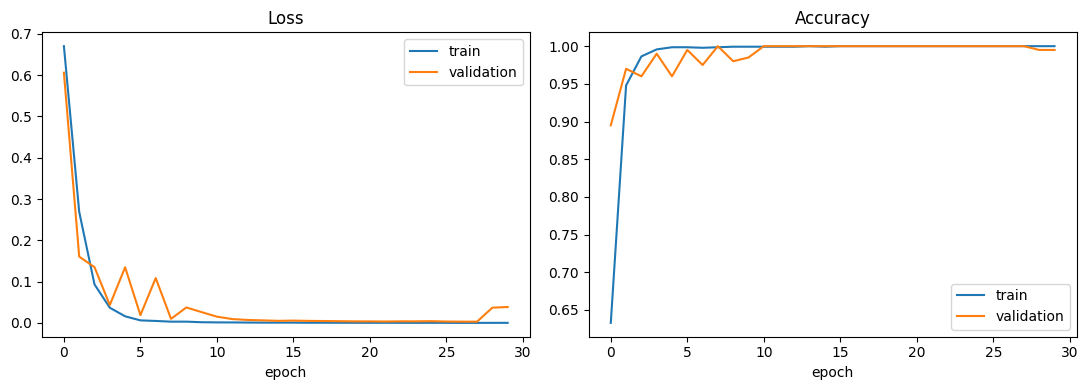

=== TEST SET RESULTS (spam = positive class) ===
Accuracy : 0.9850
Precision: 0.9583
Recall   : 0.9200
F1-score : 0.9388

              precision    recall  f1-score   support

         ham       0.99      0.99      0.99       350
        spam       0.96      0.92      0.94        50

    accuracy                           0.98       400
   macro avg       0.97      0.96      0.97       400
weighted avg       0.98      0.98      0.98       400


TASK 5 - CONFUSION MATRIX


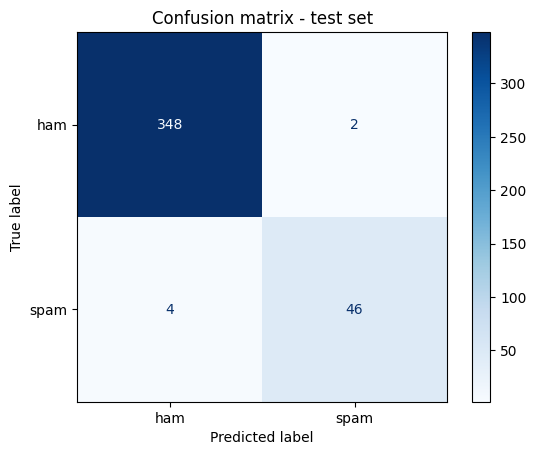

TN=348 (ham kept) | FP=2 (ham wrongly blocked) | FN=4 (spam missed) | TP=46 (spam caught)

Misclassified test messages: 6


,message,true,predicted,P(spam)
42,Hey pple...$700 or $900 for 5 nights...Excellent location wif breakfast hamper!!!,ham,spam,1.000
69,You have an important customer service announcement from PREMIER.,spam,ham,0.253
98,FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX...,spam,ham,0.000
290,"1000's flirting NOW! Txt GIRL or BLOKE & ur NAME & AGE, eg GIRL ZOE 18 to 8007 to join and get chatting!",spam,ham,0.000
293,"Did you hear about the new \Divorce Barbie\""? It comes with all of Ken's stuff!""",spam,ham,0.000
317,"Yun ah.the ubi one say if Ì_ wan call by tomorrow.call 67441233 look for irene.ere only got bus8,22,65,61,66,382. Ub...",ham,spam,1.000



TASK 5 - PREDICTIONS ON UNSEEN SMS MESSAGES


,message,P(spam),prediction
0,WINNER!! You have been selected to receive a £900 prize reward. Call 09061701461 now to claim.,1.000,SPAM
1,"Free entry in our weekly draw! Text WIN to 80086 to enter. T&Cs apply, 18+ only.",1.000,SPAM
2,URGENT! Your mobile number has won a $1000 bonus. Click http://bit.ly/claim-now to collect.,1.000,SPAM
3,Congratulations! You've been chosen for a FREE 3-day holiday. Reply YES to claim your gift.,0.989,SPAM
4,Your account has been suspended. Verify now at www.secure-bank-login.com to avoid closure.,0.000,HAM
5,"Hey, are we still meeting for lunch at 1pm? Let me know if you want to change the place.",0.000,HAM
6,Can you pick up some milk and bread on your way home? Thanks!,0.000,HAM
7,"Happy birthday! Hope you have an amazing day, see you at dinner tonight.",0.000,HAM
8,"I'll be late for the meeting, stuck in traffic. Start without me.",0.000,HAM
9,Are you free tonight? A few of us are going to watch the match.,0.000,HAM


In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import re, time, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

SEED, SUBSET_SIZE, VOCAB_SIZE, EMBED_DIM, EPOCHS, BATCH_SIZE = 42, 2000, 3000, 64, 30, 32
tf.keras.utils.set_random_seed(SEED)
def banner(t):
    print("\n" + "=" * 72 + f"\n{t}\n" + "=" * 72)

print("TensorFlow", tf.__version__)

# ===================== TASK 1: LOAD DATASET, HANDLE MISSING VALUES, PREPROCESS =====================
banner("TASK 1 - LOAD DATASET, HANDLE MISSING VALUES, PREPROCESS TEXT")

def find_csv():
    for pattern in ("/content/*.csv", "*.csv"):
        for p in glob.glob(pattern):
            if "spam" in os.path.basename(p).lower():
                return p
    try:
        import kagglehub
        folder = kagglehub.dataset_download("vishakhdapat/sms-spam-detection-dataset")
        return glob.glob(os.path.join(folder, "**", "*.csv"), recursive=True)[0]
    except Exception as e:
        raise FileNotFoundError("Dataset not found. Upload spam_sms.csv to the Colab Files panel "
                                "(folder icon on the left) and run this cell again.") from e

DATA_PATH = find_csv()
print("Using file:", DATA_PATH)

for enc in ("utf-8", "latin-1", "cp1252"):
    try:
        raw = pd.read_csv(DATA_PATH, encoding=enc); break
    except UnicodeDecodeError:
        continue

raw = raw.loc[:, ~raw.columns.astype(str).str.startswith("Unnamed")]
cols = {c.lower().strip(): c for c in raw.columns}
label_col = next((cols[k] for k in ("v1", "label", "category", "class", "type") if k in cols), raw.columns[0])
text_col  = next((cols[k] for k in ("v2", "text", "message", "sms", "content") if k in cols), raw.columns[1])
raw = raw[[label_col, text_col]].rename(columns={label_col: "label", text_col: "text"})

print("Raw shape:", raw.shape)
print("\nMissing values per column:\n", raw.isna().sum().to_string())
print("\nDuplicate messages:", raw["text"].astype(str).str.strip().duplicated().sum())
print("\nLabel counts:\n", raw["label"].value_counts().to_string())

print("--- Missing values, duplicates, labels, 2,000-message subset ---")
df = raw.dropna(subset=["label", "text"]).copy()
df["text"] = df["text"].astype(str).str.strip()
df = df[df["text"] != ""].drop_duplicates(subset="text")
df["label"] = df["label"].astype(str).str.lower().str.strip().map({"ham": 0, "spam": 1, "0": 0, "1": 1})
df = df.dropna(subset=["label"])
df["label"] = df["label"].astype(int)
print(f"After cleaning: {len(df)} messages (removed {len(raw) - len(df)})")

if len(df) > SUBSET_SIZE:
    df, _ = train_test_split(df, train_size=SUBSET_SIZE, stratify=df["label"], random_state=SEED)
df = df.reset_index(drop=True)
print(f"Subset used: {len(df)} messages | spam = {df['label'].sum()} ({df['label'].mean():.1%}) | ham = {(df['label']==0).sum()}")

print("--- Text preprocessing (raw -> clean) ---")
def clean_text(s):
    s = s.replace("å£", "£").lower()
    s = re.sub(r"(https?://\S+|www\.\S+)", " urltoken ", s)
    s = re.sub(r"\b\S+@\S+\.\S+\b", " emailtoken ", s)
    s = re.sub(r"[£$€]\s?\d+(\.\d+)?|\b\d+(\.\d+)?\s?(p|gbp|usd)\b", " moneytoken ", s)
    s = re.sub(r"\b\d{5,}\b", " longnumtoken ", s)
    s = re.sub(r"\d+", " num ", s)
    s = re.sub(r"[^a-z\s]", " ", s)
    return re.sub(r"\s+", " ", s).strip()

df["clean"] = df["text"].apply(clean_text)
for i in range(3):
    print(f"RAW   : {df['text'][i]}\nCLEAN : {df['clean'][i]}\n")

# ===================== TASK 2: TOKENIZE AND PAD SEQUENCES =====================
banner("TASK 2 - TOKENIZE AND PAD SEQUENCES")
X_train, X_tmp, y_train, y_tmp = train_test_split(
    df["clean"], df["label"], test_size=0.30, stratify=df["label"], random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(
    X_tmp, y_tmp, test_size=2/3, stratify=y_tmp, random_state=SEED)
print(f"Train: {len(X_train)} | Validation: {len(X_val)} | Test: {len(X_test)}")
print(f"Spam share -> train {y_train.mean():.3f} | val {y_val.mean():.3f} | test {y_test.mean():.3f}")

tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)
print("Distinct words in training set:", len(tokenizer.word_index))

MAX_LEN = int(np.percentile([len(t.split()) for t in X_train], 95))
print("MAX_LEN (95th percentile of message length):", MAX_LEN)

def to_padded(texts):
    return pad_sequences(tokenizer.texts_to_sequences(texts), maxlen=MAX_LEN, padding="post", truncating="post")

Xtr, Xva, Xte = to_padded(X_train), to_padded(X_val), to_padded(X_test)
ytr, yva, yte = y_train.values, y_val.values, y_test.values
print("Padded shapes:", Xtr.shape, Xva.shape, Xte.shape)

k = 0
print("\nText     :", X_train.iloc[k])
print("Sequence :", tokenizer.texts_to_sequences([X_train.iloc[k]])[0])
print("Padded   :", Xtr[k])

# ===================== TASK 3: MODEL (GRU) + COMPARISON WITH RNN / LSTM =====================
banner("TASK 3 - MODEL: GRU")
def build_model(cell="gru"):
    rnn_layer = {"rnn": layers.SimpleRNN, "lstm": layers.LSTM, "gru": layers.GRU}[cell]
    m = models.Sequential([
        layers.Input(shape=(MAX_LEN,)),
        layers.Embedding(VOCAB_SIZE, EMBED_DIM, mask_zero=True),
        rnn_layer(64),
        layers.Dropout(0.4),
        layers.Dense(32, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(1, activation="sigmoid"),
    ], name=f"{cell}_spam_classifier")
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="binary_crossentropy", metrics=["accuracy"])
    return m

w = compute_class_weight("balanced", classes=np.array([0, 1]), y=ytr)
class_weight = {0: float(w[0]), 1: float(w[1])}
print("Class weights:", {k: round(v, 2) for k, v in class_weight.items()})

def fit_model(m, verbose=0):
    stop = callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)
    return m.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=EPOCHS, batch_size=BATCH_SIZE,
                 class_weight=class_weight, callbacks=[stop], verbose=verbose)

tf.keras.utils.set_random_seed(SEED)
model = build_model("gru")
model.summary()

banner("TASK 3 (cont.) - RNN vs LSTM vs GRU (validation set)")
rows = []
for cell in ("rnn", "lstm", "gru"):
    tf.keras.utils.set_random_seed(SEED)
    m = build_model(cell)
    t0 = time.time()
    h = fit_model(m)
    pred = (m(Xva, training=False).numpy().ravel() >= 0.5).astype(int)
    rows.append({"model": cell.upper(), "parameters": m.count_params(), "epochs run": len(h.history["loss"]),
                 "train time (s)": round(time.time() - t0, 1),
                 "val accuracy": accuracy_score(yva, pred), "val precision": precision_score(yva, pred, zero_division=0),
                 "val recall": recall_score(yva, pred, zero_division=0), "val F1": f1_score(yva, pred, zero_division=0)})
display(pd.DataFrame(rows).round(3))

# ===================== TASK 4: TRAIN AND EVALUATE =====================
banner("TASK 4 - TRAINING THE GRU")
tf.keras.utils.set_random_seed(SEED)
model = build_model("gru")
history = fit_model(model, verbose=2)

banner("TASK 4 - EVALUATION (ACCURACY, PRECISION, RECALL, F1)")
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history.history["loss"], label="train");     ax[0].plot(history.history["val_loss"], label="validation")
ax[0].set_title("Loss");     ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(history.history["accuracy"], label="train"); ax[1].plot(history.history["val_accuracy"], label="validation")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

test_prob = model.predict(Xte, verbose=0).ravel()
test_pred = (test_prob >= 0.5).astype(int)

print("=== TEST SET RESULTS (spam = positive class) ===")
print(f"Accuracy : {accuracy_score(yte, test_pred):.4f}")
print(f"Precision: {precision_score(yte, test_pred, zero_division=0):.4f}")
print(f"Recall   : {recall_score(yte, test_pred, zero_division=0):.4f}")
print(f"F1-score : {f1_score(yte, test_pred, zero_division=0):.4f}\n")
print(classification_report(yte, test_pred, target_names=["ham", "spam"], zero_division=0))

# ===================== TASK 5: CONFUSION MATRIX AND UNSEEN PREDICTIONS =====================
banner("TASK 5 - CONFUSION MATRIX")
cm = confusion_matrix(yte, test_pred)
ConfusionMatrixDisplay(cm, display_labels=["ham", "spam"]).plot(cmap="Blues", values_format="d")
plt.title("Confusion matrix - test set"); plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"TN={tn} (ham kept) | FP={fp} (ham wrongly blocked) | FN={fn} (spam missed) | TP={tp} (spam caught)")

errors = pd.DataFrame({"message": df.loc[X_test.index, "text"].values,
                       "true": np.where(yte == 1, "spam", "ham"),
                       "predicted": np.where(test_pred == 1, "spam", "ham"),
                       "P(spam)": test_prob.round(3)})
errors = errors[errors["true"] != errors["predicted"]]
print(f"\nMisclassified test messages: {len(errors)}")
with pd.option_context("display.max_colwidth", 120, "display.width", 220):
    display(errors)

banner("TASK 5 - PREDICTIONS ON UNSEEN SMS MESSAGES")
def predict_sms(messages, threshold=0.5):
    probs = model.predict(to_padded([clean_text(m) for m in messages]), verbose=0).ravel()
    out = pd.DataFrame({"message": messages, "P(spam)": probs.round(3),
                        "prediction": np.where(probs >= threshold, "SPAM", "HAM")})
    with pd.option_context("display.max_colwidth", 110, "display.width", 220):
        display(out)

unseen = [
    "WINNER!! You have been selected to receive a £900 prize reward. Call 09061701461 now to claim.",
    "Free entry in our weekly draw! Text WIN to 80086 to enter. T&Cs apply, 18+ only.",
    "URGENT! Your mobile number has won a $1000 bonus. Click http://bit.ly/claim-now to collect.",
    "Congratulations! You've been chosen for a FREE 3-day holiday. Reply YES to claim your gift.",
    "Your account has been suspended. Verify now at www.secure-bank-login.com to avoid closure.",
    "Hey, are we still meeting for lunch at 1pm? Let me know if you want to change the place.",
    "Can you pick up some milk and bread on your way home? Thanks!",
    "Happy birthday! Hope you have an amazing day, see you at dinner tonight.",
    "I'll be late for the meeting, stuck in traffic. Start without me.",
    "Are you free tonight? A few of us are going to watch the match.",
]
predict_sms(unseen)